In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
DATA_PATH = r"C:\screen_designer\Tags.xlsx"

df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (815, 5)


In [5]:
df.head(10)

,Project,Access,PLC tag,data type,Lable
0,Yamaha,ReadOnly,PC_PLC_COMM_FAULT,Boolean,1
1,Yamaha,WriteOnly,PC_MAINT_MODE_ON_ST1,Boolean,3
2,Yamaha,WriteOnly,PC_M_EXA_HOOD_OPEN,Boolean,3
3,Yamaha,WriteOnly,PC_M_EXA_BLWR_ON,Boolean,3
4,Yamaha,WriteOnly,PC_M_FW_CLAMP_ST1,Boolean,3
5,Yamaha,WriteOnly,PC_M_LIFTER_DOWN_ST1,Boolean,3
6,Yamaha,WriteOnly,PC_M_VENT_BLWR_1_ON,Boolean,3
7,Yamaha,WriteOnly,PC_M_VENT_BLWR_2_ON,Boolean,3
8,Yamaha,ReadOnly,EMG_OFF_ST2_FAULT,Boolean,1
9,Yamaha,ReadOnly,CON_PANEL_EMG_OFF_FAULT,Boolean,1


In [6]:
df.tail(10)

,Project,Access,PLC tag,data type,Lable
805,WOR,ReadOnly,HORN_VALUE,Real,0
806,WOR,ReadOnly,DRIVE_TORQUE,Real,0
807,WOR,WriteOnly,PC_R0,Real,0
808,WOR,WriteOnly,PC_R1,Real,0
809,WOR,WriteOnly,PC_R2,Real,0
810,WOR,WriteOnly,LUB_TIME,Real,0
811,WOR,WriteOnly,LUB_INTERVAL,Real,0
812,WOR,WriteOnly,PC_GRADIENT_FORCE,Real,0
813,WOR,WriteOnly,MODEL_MAX_SPEED,Real,0
814,WOR,WriteAutomatically,ENR_METER_PARAMETER1,Real,0


In [7]:
df.sample(10, random_state=RANDOM_STATE)

,Project,Access,PLC tag,data type,Lable
196,Yamaha,ReadOnly,Stage2_actForce,Real,0
299,CG,ReadOnly,PLC_LIFTER_UP_FAULT,Boolean,1
388,CG,ReadOnly,PLC_OBD_CONNECT_FW_PEND_FLT,Boolean,1
227,Yamaha,ReadOnly,STRT_FTSW_TESTPEN,Boolean,0
664,WOR,ReadOnly,VEH_COOL_BLWR_TRIP_FAULT,Boolean,1
801,WOR,ReadOnly,FW_LOADCELL_MV,Real,0
199,Yamaha,WriteOnly,L2_VALUE,Real,0
336,CG,ReadOnly,PLC_ROTARY_HOOD_CLOSE_FLT,Boolean,1
338,CG,ReadOnly,PLC_PHASE_FAIL_PREVENTER_FLT,Boolean,1
528,Suzuki,WriteOnly,V0_VALUE,Real,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 815 entries, 0 to 814
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Project     815 non-null    str  
 1   Access      815 non-null    str  
 2   PLC tag     815 non-null    str  
 3   data type   815 non-null    str  
 4   Lable       815 non-null    int64
dtypes: int64(1), str(4)
memory usage: 62.0 KB


In [9]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
for col in df.columns:
    print(repr(col))

Rows: 815
Columns: 5

Column names:
'Project'
'Access'
'PLC tag'
'data type '
'Lable'


In [10]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

df.columns

Index(['project', 'access', 'plc_tag', 'data_type', 'lable'], dtype='str')

In [11]:
df = df.rename(columns={
    "lable": "label"
})

df.columns

Index(['project', 'access', 'plc_tag', 'data_type', 'label'], dtype='str')

In [12]:
missing = df.isnull().sum()

missing

project      0
access       0
plc_tag      0
data_type    0
label        0
dtype: int64

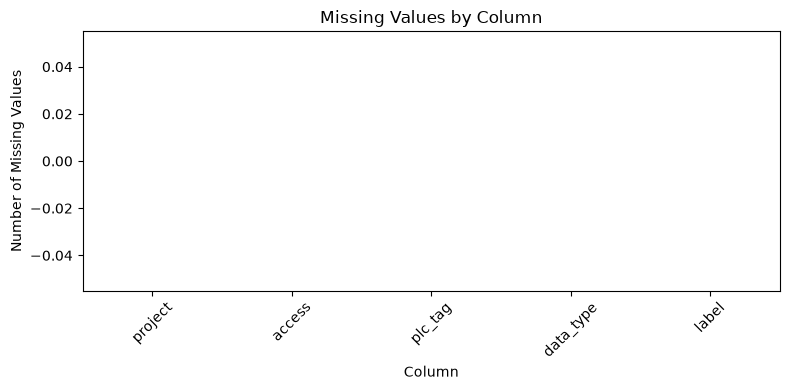

In [13]:
plt.figure(figsize=(8, 4))

sns.barplot(
    x=missing.index,
    y=missing.values
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
df.dtypes

project        str
access         str
plc_tag        str
data_type      str
label        int64
dtype: object

In [15]:
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(20))


--- project ---
project
Yamaha    292
CG        227
WOR       199
Suzuki     53
TVS        44
Name: count, dtype: int64

--- access ---
access
ReadOnly              653
WriteOnly             155
WriteAutomatically      6
ReadWrite               1
Name: count, dtype: int64

--- plc_tag ---
plc_tag
PC_M_EXA_BLWR_ON            3
LUB_OIL_PRESSURE_FAULT      3
DRIVE_FAULT                 3
PC_BASE_INERTIA             3
PC_WARMUP_BIT               3
PC_PLC_COMM_FAULT           2
PC_M_EXA_HOOD_OPEN          2
CON_PANEL_EMG_OFF_FAULT     2
PHASE_FAIL_PREV_FAULT       2
LUB_OIL_MOTOR_TRIP_FAULT    2
LUB_OIL_ON_FAULT            2
EXH_BLOWER_TRIP_FAULT       2
LUB_OIL_LOW_LEVEL_FAULT     2
EXHAUST_HOOD_OPEN_FB        2
PHASE_FAIL_PREV_FB          2
LUB_OIL_LOW_LEVEL_FB        2
ST1_AIR_PRESS_FLT           2
EXH_BLOW_START_OP           2
ST2_FRONTCLMP_RH_FLT        2
MAINT_LAMP                  2
Name: count, dtype: int64

--- data_type ---
data_type
Boolean    693
Real       114
Integer      7
i

In [16]:
df["project"] = (
    df["project"]
    .astype(str)
    .str.strip()
)

df["access"] = (
    df["access"]
    .astype(str)
    .str.strip()
)

df["plc_tag"] = (
    df["plc_tag"]
    .astype(str)
    .str.strip()
)

df["data_type"] = (
    df["data_type"]
    .astype(str)
    .str.strip()
    .str.lower()
)

In [17]:
df["data_type"].value_counts()

data_type
boolean    693
real       114
integer      8
Name: count, dtype: int64

In [18]:
df["label"].value_counts().sort_index()

label
0    270
1    271
2    206
3     68
Name: count, dtype: int64

In [19]:
valid_labels = {0, 1, 2, 3}

invalid_labels = df.loc[
    ~df["label"].isin(valid_labels),
    "label"
]

print("Invalid labels:")
print(invalid_labels.unique())

Invalid labels:
[]


In [20]:
label_names = {
    0: "Other",
    1: "Fault",
    2: "I/O",
    3: "Maintenance"
}

df["label_name"] = df["label"].map(label_names)

df[["plc_tag", "label", "label_name"]].head(20)

,plc_tag,label,label_name
0,PC_PLC_COMM_FAULT,1,Fault
1,PC_MAINT_MODE_ON_ST1,3,Maintenance
2,PC_M_EXA_HOOD_OPEN,3,Maintenance
3,PC_M_EXA_BLWR_ON,3,Maintenance
4,PC_M_FW_CLAMP_ST1,3,Maintenance
5,PC_M_LIFTER_DOWN_ST1,3,Maintenance
6,PC_M_VENT_BLWR_1_ON,3,Maintenance
7,PC_M_VENT_BLWR_2_ON,3,Maintenance
8,EMG_OFF_ST2_FAULT,1,Fault
9,CON_PANEL_EMG_OFF_FAULT,1,Fault


In [21]:
duplicate_rows = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_rows)

Exact duplicate rows: 22


In [22]:
df[df.duplicated(keep=False)].sort_values(
    ["plc_tag", "project"]
)

,project,access,plc_tag,data_type,label,label_name
9,Yamaha,ReadOnly,CON_PANEL_EMG_OFF_FAULT,boolean,1,Fault
94,Yamaha,ReadOnly,CON_PANEL_EMG_OFF_FAULT,boolean,1,Fault
20,Yamaha,ReadOnly,EXH_BLOWER_TRIP_FAULT,boolean,1,Fault
183,Yamaha,ReadOnly,EXH_BLOWER_TRIP_FAULT,boolean,1,Fault
84,Yamaha,ReadOnly,EXH_BLOW_HLTHY_FB,boolean,2,I/O
136,Yamaha,ReadOnly,EXH_BLOW_HLTHY_FB,boolean,2,I/O
73,Yamaha,ReadOnly,EXH_BLOW_START_OP,boolean,2,I/O
184,Yamaha,ReadOnly,EXH_BLOW_START_OP,boolean,2,I/O
85,Yamaha,ReadOnly,HEAD_LIT_PLNK_HOM_POS_FB,boolean,2,I/O
186,Yamaha,ReadOnly,HEAD_LIT_PLNK_HOM_POS_FB,boolean,2,I/O


In [23]:
tag_counts = (
    df["plc_tag"]
    .value_counts()
)

tag_counts.head(20)

plc_tag
PC_M_EXA_BLWR_ON            3
LUB_OIL_PRESSURE_FAULT      3
DRIVE_FAULT                 3
PC_BASE_INERTIA             3
PC_WARMUP_BIT               3
PC_PLC_COMM_FAULT           2
PC_M_EXA_HOOD_OPEN          2
CON_PANEL_EMG_OFF_FAULT     2
PHASE_FAIL_PREV_FAULT       2
LUB_OIL_MOTOR_TRIP_FAULT    2
LUB_OIL_ON_FAULT            2
EXH_BLOWER_TRIP_FAULT       2
LUB_OIL_LOW_LEVEL_FAULT     2
EXHAUST_HOOD_OPEN_FB        2
PHASE_FAIL_PREV_FB          2
LUB_OIL_LOW_LEVEL_FB        2
ST1_AIR_PRESS_FLT           2
EXH_BLOW_START_OP           2
ST2_FRONTCLMP_RH_FLT        2
MAINT_LAMP                  2
Name: count, dtype: int64

In [24]:
repeated_tags = tag_counts[tag_counts > 1]

print("Unique PLC tags:", df["plc_tag"].nunique())
print("Total rows:", len(df))
print("Repeated PLC tags:", len(repeated_tags))

Unique PLC tags: 762
Total rows: 815
Repeated PLC tags: 48


In [25]:
repeated_tags.head(30)

plc_tag
PC_M_EXA_BLWR_ON            3
LUB_OIL_PRESSURE_FAULT      3
DRIVE_FAULT                 3
PC_BASE_INERTIA             3
PC_WARMUP_BIT               3
PC_PLC_COMM_FAULT           2
PC_M_EXA_HOOD_OPEN          2
CON_PANEL_EMG_OFF_FAULT     2
PHASE_FAIL_PREV_FAULT       2
LUB_OIL_MOTOR_TRIP_FAULT    2
LUB_OIL_ON_FAULT            2
EXH_BLOWER_TRIP_FAULT       2
LUB_OIL_LOW_LEVEL_FAULT     2
EXHAUST_HOOD_OPEN_FB        2
PHASE_FAIL_PREV_FB          2
LUB_OIL_LOW_LEVEL_FB        2
ST1_AIR_PRESS_FLT           2
EXH_BLOW_START_OP           2
ST2_FRONTCLMP_RH_FLT        2
MAINT_LAMP                  2
LUB_MOT_TRIP_FB             2
LUB_MOT_ON_FB               2
EXH_BLOW_HLTHY_FB           2
HEAD_LIT_PLNK_HOM_POS_FB    2
HEAD_LIT_PLNK_WRK_POS_FB    2
AIR_PRESSURE_FB             2
A_VALUE                     2
B_VALUE                     2
C_VALUE                     2
V0_VALUE                    2
Name: count, dtype: int64

In [26]:
tag_label_counts = (
    df.groupby("plc_tag")["label"]
    .nunique()
)

conflicting_tags = tag_label_counts[
    tag_label_counts > 1
]

print(
    "PLC tags with conflicting labels:",
    len(conflicting_tags)
)

conflicting_tags

PLC tags with conflicting labels: 1


plc_tag
ST1_AIR_PRESS_FLT    2
Name: label, dtype: int64

In [27]:
df[
    df["plc_tag"].isin(conflicting_tags.index)
].sort_values("plc_tag")

,project,access,plc_tag,data_type,label,label_name
54,Yamaha,ReadOnly,ST1_AIR_PRESS_FLT,boolean,1,Fault
226,Yamaha,ReadOnly,ST1_AIR_PRESS_FLT,boolean,0,Other


In [28]:
# Show exact duplicate rows
duplicates = df[df.duplicated(keep=False)].sort_values(
    by=["plc_tag", "project"]
)

print("Number of duplicate rows:", len(duplicates))

duplicates

Number of duplicate rows: 44


,project,access,plc_tag,data_type,label,label_name
9,Yamaha,ReadOnly,CON_PANEL_EMG_OFF_FAULT,boolean,1,Fault
94,Yamaha,ReadOnly,CON_PANEL_EMG_OFF_FAULT,boolean,1,Fault
20,Yamaha,ReadOnly,EXH_BLOWER_TRIP_FAULT,boolean,1,Fault
183,Yamaha,ReadOnly,EXH_BLOWER_TRIP_FAULT,boolean,1,Fault
84,Yamaha,ReadOnly,EXH_BLOW_HLTHY_FB,boolean,2,I/O
136,Yamaha,ReadOnly,EXH_BLOW_HLTHY_FB,boolean,2,I/O
73,Yamaha,ReadOnly,EXH_BLOW_START_OP,boolean,2,I/O
184,Yamaha,ReadOnly,EXH_BLOW_START_OP,boolean,2,I/O
85,Yamaha,ReadOnly,HEAD_LIT_PLNK_HOM_POS_FB,boolean,2,I/O
186,Yamaha,ReadOnly,HEAD_LIT_PLNK_HOM_POS_FB,boolean,2,I/O


In [29]:
# Find PLC tags that have more than one label
conflicting_tags = (
    df.groupby("plc_tag")["label"]
      .nunique()
      .loc[lambda x: x > 1]
)

print("Number of PLC tags with conflicting labels:", len(conflicting_tags))

conflicting_tags

Number of PLC tags with conflicting labels: 1


plc_tag
ST1_AIR_PRESS_FLT    2
Name: label, dtype: int64

In [30]:
df[df["plc_tag"] == "ST1_AIR_PRESS_FLT"]

,project,access,plc_tag,data_type,label,label_name
54,Yamaha,ReadOnly,ST1_AIR_PRESS_FLT,boolean,1,Fault
226,Yamaha,ReadOnly,ST1_AIR_PRESS_FLT,boolean,0,Other


In [31]:
df.loc[df["plc_tag"] == "ST1_AIR_PRESS_FLT","label"] = 1

In [32]:
df.loc[df["plc_tag"] == "ST1_AIR_PRESS_FLT","label_name"] = "Fault"

In [33]:
df[df["plc_tag"] == "ST1_AIR_PRESS_FLT"]

,project,access,plc_tag,data_type,label,label_name
54,Yamaha,ReadOnly,ST1_AIR_PRESS_FLT,boolean,1,Fault
226,Yamaha,ReadOnly,ST1_AIR_PRESS_FLT,boolean,1,Fault


In [34]:
print("Rows before:", len(df))

df = df.drop_duplicates().reset_index(drop=True)

print("Rows after:", len(df))
print("Rows removed:", 811 - len(df))

Rows before: 815
Rows after: 792
Rows removed: 19


In [35]:
# Check if any exact duplicate rows remain

print("Exact duplicate rows remaining:",
      df.duplicated().sum())

Exact duplicate rows remaining: 0


In [36]:
conflicting_tags = (
    df.groupby("plc_tag")["label"]
      .nunique()
      .loc[lambda x: x > 1]
)

print("PLC tags with conflicting labels:", len(conflicting_tags))

conflicting_tags

PLC tags with conflicting labels: 0


Series([], Name: label, dtype: int64)

In [37]:
label_counts = df["label_name"].value_counts()

print(label_counts)

label_name
Other          265
Fault          262
I/O            199
Maintenance     66
Name: count, dtype: int64


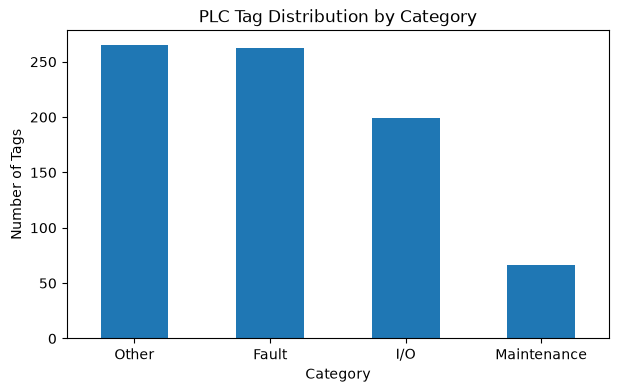

In [38]:
label_counts.plot(
    kind="bar",
    figsize=(7, 4),
    title="PLC Tag Distribution by Category"
)

plt.xlabel("Category")
plt.ylabel("Number of Tags")
plt.xticks(rotation=0)
plt.show()

In [39]:
project_label_counts = pd.crosstab(
    df["project"],
    df["label_name"]
)

project_label_counts

label_name,Fault,I/O,Maintenance,Other
project,,,,
CG,77,46,8,94
Suzuki,12,3,6,32
TVS,21,19,4,0
WOR,72,50,33,44
Yamaha,80,81,15,95


In [40]:
X = df[["plc_tag", "access", "data_type"]].copy()
y = df["label"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (792, 3)
y shape: (792,)


,plc_tag,access,data_type
0,PC_PLC_COMM_FAULT,ReadOnly,boolean
1,PC_MAINT_MODE_ON_ST1,WriteOnly,boolean
2,PC_M_EXA_HOOD_OPEN,WriteOnly,boolean
3,PC_M_EXA_BLWR_ON,WriteOnly,boolean
4,PC_M_FW_CLAMP_ST1,WriteOnly,boolean


In [39]:
from sklearn.model_selection import LeaveOneGroupOut

groups = df["project"]

logo = LeaveOneGroupOut()

print("Number of validation folds:", logo.get_n_splits(X, y, groups))
print("Projects:", groups.unique())

Number of validation folds: 5
Projects: <ArrowStringArray>
['Yamaha', 'CG', 'Suzuki', 'TVS', 'WOR']
Length: 5, dtype: str


In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=1
    )),
    ("clf", LogisticRegression(
        max_iter=2000
    ))
])

In [41]:
from sklearn.metrics import accuracy_score, classification_report

results = []

for train_idx, test_idx in logo.split(X, y, groups):

    X_train = X.iloc[train_idx]["plc_tag"]
    X_test = X.iloc[test_idx]["plc_tag"]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Store results
    results.append({
        "test_project": groups.iloc[test_idx].iloc[0],
        "accuracy": accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df

,test_project,accuracy
0,CG,0.911111
1,Suzuki,0.867925
2,TVS,0.954545
3,WOR,0.969849
4,Yamaha,0.922509


In [42]:
# Evaluate the model specifically on CG

train_idx, test_idx = next(
    logo.split(X, y, groups)
)

# The first fold should be CG based on our results
test_project = groups.iloc[test_idx].iloc[0]

print("Test project:", test_project)

X_train = X.iloc[train_idx]["plc_tag"]
X_test = X.iloc[test_idx]["plc_tag"]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Test project: CG


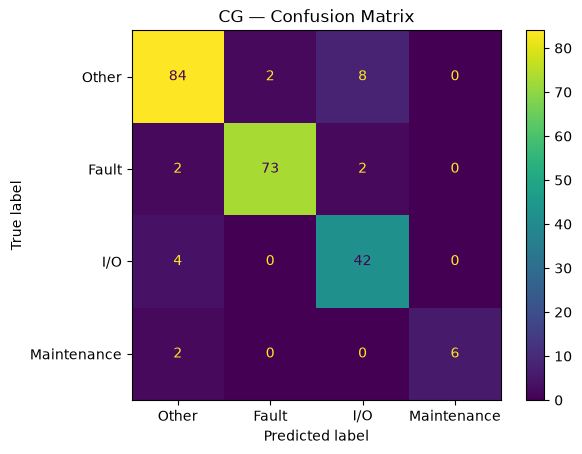

In [43]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Other", "Fault", "I/O", "Maintenance"]
)

disp.plot()
plt.title("CG — Confusion Matrix")
plt.show()

In [44]:
cg_errors = X_test.copy()

cg_errors = pd.DataFrame({
    "plc_tag": X_test.values,
    "actual": y_test.values,
    "predicted": y_pred
})

cg_errors = cg_errors[
    cg_errors["actual"] != cg_errors["predicted"]
].copy()

cg_errors["actual_name"] = cg_errors["actual"].map(label_names)
cg_errors["predicted_name"] = cg_errors["predicted"].map(label_names)

cg_errors

,plc_tag,actual,predicted,actual_name,predicted_name
10,PLC_LUB_OIL_LOW_PRESS_FLT,1,2,Fault,I/O
19,PLC_DYNO_OVER_SPEED_FLT,1,0,Fault,Other
86,PLC_24V_SHORT_CKT_PROT_FLT,1,2,Fault,I/O
102,PLC_TS_EXH_HOOD_CLOSE_SOL_OP,2,0,I/O,Other
103,PLC_TS_EXH_HOOD_OPEN_SOL_OP,2,0,I/O,Other
115,PLC_HLT_AT_HOME_OP,2,0,I/O,Other
116,PLC_HLT_AT_WORK_POSITION_OP,2,0,I/O,Other
121,PLC_VEHICLE_OVER_SPEED_FLT,1,0,Fault,Other
139,PC_M_RW_SPEED_DEMAND,3,0,Maintenance,Other
150,PLC_FW_REVOLUTION_COUNT,0,2,Other,I/O


In [45]:
flt_tags = df[
    df["plc_tag"].str.contains(r"_FLT$", case=False, regex=True, na=False)
]

flt_distribution = (
    flt_tags["label_name"]
    .value_counts()
    .to_frame("count")
)

flt_distribution["percentage"] = (
    flt_distribution["count"] / len(flt_tags) * 100
)

print("Total tags ending with _FLT:", len(flt_tags))
flt_distribution

Total tags ending with _FLT: 62


,count,percentage
label_name,,
Fault,62,100.0


In [46]:
# Check whether "_flt" exists as a learned TF-IDF feature

tfidf = model.named_steps["tfidf"]

features = tfidf.get_feature_names_out()

flt_features = [
    feature for feature in features
    if "_flt" in feature
]

print("Number of features containing '_flt':", len(flt_features))
print(flt_features[:50])

Number of features containing '_flt': 15
[' _flt', '1_flt', '_flt', '_flt_', 'd_flt', 'e_flt', 'g_flt', 'h_flt', 'm_flt', 'n_flt', 'p_flt', 's_flt', 'v_flt', 'w_flt', 'y_flt']


In [47]:
import numpy as np

tfidf = model.named_steps["tfidf"]
clf = model.named_steps["clf"]

features = tfidf.get_feature_names_out()

flt_index = np.where(features == "_flt")[0][0]

classes = clf.classes_
coefficients = clf.coef_[:, flt_index]

pd.DataFrame({
    "class": classes,
    "class_name": [label_names[c] for c in classes],
    "_flt_coefficient": coefficients
})

,class,class_name,_flt_coefficient
0,0,Other,-0.334628
1,1,Fault,1.149125
2,2,I/O,-0.667035
3,3,Maintenance,-0.147462


In [48]:
# Look specifically at _FLT tags that the model misclassified

flt_test = X_test[
    X_test.str.contains(r"FLT", case=False, regex=True, na=False)
]

flt_actual = y_test.loc[flt_test.index]

flt_pred = model.predict(flt_test)
flt_prob = model.predict_proba(flt_test)

flt_errors = pd.DataFrame({
    "plc_tag": flt_test.values,
    "actual": flt_actual.values,
    "predicted": flt_pred
})

# Add probability for each class
for i, cls in enumerate(model.named_steps["clf"].classes_):
    flt_errors[f"prob_{label_names[cls]}"] = flt_prob[:, i]

flt_errors = flt_errors[
    flt_errors["actual"] != flt_errors["predicted"]
]

flt_errors

,plc_tag,actual,predicted,prob_Other,prob_Fault,prob_I/O,prob_Maintenance
1,PLC_LUB_OIL_LOW_PRESS_FLT,1,2,0.119338,0.385258,0.457629,0.037775
3,PLC_DYNO_OVER_SPEED_FLT,1,0,0.633972,0.238001,0.083623,0.044405
22,PLC_24V_SHORT_CKT_PROT_FLT,1,2,0.265589,0.317481,0.352324,0.064605
38,PLC_VEHICLE_OVER_SPEED_FLT,1,0,0.539919,0.297395,0.102156,0.060531


In [49]:
# Create individual underscore-separated tokens
token_rows = []

for _, row in df.iterrows():
    tokens = set(row["plc_tag"].split("_"))
    
    for token in tokens:
        token_rows.append({
            "token": token,
            "label": row["label"]
        })

token_df = pd.DataFrame(token_rows)

# Count how many tags contain each token
token_counts = token_df.groupby("token")["label"].count()

# Count labels for each token
token_label_counts = pd.crosstab(
    token_df["token"],
    token_df["label"]
)

# Keep tokens appearing at least 5 times
common_tokens = token_counts[token_counts >= 5].index

token_label_counts = token_label_counts.loc[
    token_label_counts.index.isin(common_tokens)
]

token_label_counts

label,0,1,2,3
token,,,,
1,3,5,7,2
2,3,5,5,3
A,6,0,0,0
ABS,5,0,0,0
ACT,6,0,0,0
...,...,...,...,...
VECH,0,2,4,1
VEH,3,5,3,1
VENT,2,4,4,3


In [50]:
token_percent = token_label_counts.div(
    token_label_counts.sum(axis=1),
    axis=0
) * 100

token_percent.round(1)

label,0,1,2,3
token,,,,
1,17.6,29.4,41.2,11.8
2,18.8,31.2,31.2,18.8
A,100.0,0.0,0.0,0.0
ABS,100.0,0.0,0.0,0.0
ACT,100.0,0.0,0.0,0.0
...,...,...,...,...
VECH,0.0,28.6,57.1,14.3
VEH,25.0,41.7,25.0,8.3
VENT,15.4,30.8,30.8,23.1


In [51]:
token_analysis = pd.DataFrame({
    "count": token_counts,
    "Other_%": token_percent[0],
    "Fault_%": token_percent[1],
    "IO_%": token_percent[2],
    "Maintenance_%": token_percent[3]
})

# Show tokens that have at least 5 occurrences,
# sorted by strongest association with any one class

token_analysis["max_percentage"] = token_analysis[
    ["Other_%", "Fault_%", "IO_%", "Maintenance_%"]
].max(axis=1)

strong_tokens = (
    token_analysis[
        token_analysis["count"] >= 5
    ]
    .sort_values("max_percentage", ascending=False)
)

strong_tokens.head(30)

,count,Other_%,Fault_%,IO_%,Maintenance_%,max_percentage
token,,,,,,
ABS,5,100.0,0.0,0.0,0.0,100.0
A,6,100.0,0.0,0.0,0.0,100.0
RESET,15,0.0,100.0,0.0,0.0,100.0
PNDT,5,100.0,0.0,0.0,0.0,100.0
ACT,6,100.0,0.0,0.0,0.0,100.0
ACTUAL,7,100.0,0.0,0.0,0.0,100.0
BIT,7,100.0,0.0,0.0,0.0,100.0
B,5,100.0,0.0,0.0,0.0,100.0
CLMP,9,0.0,0.0,100.0,0.0,100.0


In [52]:
df[df["plc_tag"].str.contains("FLT", case=False, na=False)][
    ["plc_tag", "label_name"]
].head(20)

,plc_tag,label_name
54,ST1_AIR_PRESS_FLT,Fault
74,EXH_BLOW_FLT_RES_OP,Fault
75,ST2_FRONTCLMP_RH_FLT,Fault
76,ST2_FRONTDECLMP_RH_FLT,Fault
77,ST2_FRONTDECLMP_LH_FLT,Fault
78,ST2_TEL_EXH_OPEN_FLT,Fault
79,ST2_TEL_EXH_CLOSE_FLT,Fault
117,ROTARY_HOOD_ENG_FLT,Fault
119,ROTARY_HOOD_DISENG_FLT,Fault
120,ST2_AIR_PRESS_FLT,Fault


In [53]:
print(
    "Total tags containing FLT:",
    df["plc_tag"].str.contains("FLT", case=False, na=False).sum()
)

Total tags containing FLT: 83


In [54]:
token_rows = []

for _, row in df.iterrows():
    tokens = set(row["plc_tag"].split("_"))

    for token in tokens:
        token_rows.append({
            "token": token,
            "label": row["label"]
        })

token_df = pd.DataFrame(token_rows)

token_counts = token_df.groupby("token")["label"].count()

token_label_counts = pd.crosstab(
    token_df["token"],
    token_df["label"]
)

token_percent = token_label_counts.div(
    token_label_counts.sum(axis=1),
    axis=0
) * 100

In [55]:
token_analysis.loc["FLT"] if "FLT" in token_analysis.index else "FLT not found"

count             83.000000
Other_%            1.204819
Fault_%           98.795181
IO_%               0.000000
Maintenance_%      0.000000
max_percentage    98.795181
Name: FLT, dtype: float64

In [56]:
token_analysis = pd.DataFrame({
    "count": token_counts,
    "Other_%": token_percent[0],
    "Fault_%": token_percent[1],
    "IO_%": token_percent[2],
    "Maintenance_%": token_percent[3]
})

token_analysis.loc["FLT"]

count            83.000000
Other_%           1.204819
Fault_%          98.795181
IO_%              0.000000
Maintenance_%     0.000000
Name: FLT, dtype: float64

In [57]:
from sklearn.pipeline import FeatureUnion

char_features = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    min_df=1
)

word_features = TfidfVectorizer(
    analyzer="word",
    token_pattern=r"(?u)\b\w+\b",
    ngram_range=(1, 2),
    min_df=1
)

combined_model = Pipeline([
    ("features", FeatureUnion([
        ("char", char_features),
        ("word", word_features)
    ])),
    ("clf", LogisticRegression(
        max_iter=2000
    ))
])

In [58]:
combined_results = []

for train_idx, test_idx in logo.split(X, y, groups):

    X_train = X.iloc[train_idx]["plc_tag"]
    X_test = X.iloc[test_idx]["plc_tag"]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    combined_model.fit(X_train, y_train)

    y_pred = combined_model.predict(X_test)

    combined_results.append({
        "test_project": groups.iloc[test_idx].iloc[0],
        "accuracy": accuracy_score(y_test, y_pred)
    })

combined_results_df = pd.DataFrame(combined_results)

combined_results_df

,test_project,accuracy
0,CG,0.897778
1,Suzuki,0.811321
2,TVS,0.931818
3,WOR,0.914573
4,Yamaha,0.904059


In [59]:
df.loc[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN", "label"] = 1
df.loc[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN", "label_name"] = "Fault"

In [60]:
df[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN"]

,project,access,plc_tag,data_type,label,label_name
217,Yamaha,ReadOnly,ST1_FLT_LAMP_CTR_PAN,boolean,1,Fault


In [61]:
token_summary = token_analysis.copy()

token_summary["total_count"] = (
    token_summary[["0_count", "1_count", "2_count", "3_count"]].sum(axis=1)
)

token_summary["max_class_%"] = (
    token_summary[["0_%", "1_%", "2_%", "3_%"]].max(axis=1)
)

token_summary[
    (token_summary["total_count"] >= 5) &
    (token_summary["max_class_%"] == 100)
].sort_values("total_count", ascending=False)

KeyError: "None of [Index(['0_count', '1_count', '2_count', '3_count'], dtype='str')] are in the [columns]"

In [62]:
X_domain = pd.DataFrame(index=df.index)


In [63]:
X_domain["has_fault"] = (
    df["plc_tag"]
    .str.contains("FAULT", case=False, na=False)
    .astype(int)
)

X_domain["has_emg"] = (
    df["plc_tag"]
    .str.contains("EMG", case=False, na=False)
    .astype(int)
)

X_domain["has_fb"] = (
    df["plc_tag"]
    .str.contains(r"(^|_)FB(_|$)", case=False, regex=True, na=False)
    .astype(int)
)

X_domain["has_maint"] = (
    df["plc_tag"]
    .str.contains("MAINT", case=False, na=False)
    .astype(int)
)

X_domain["has_maintenance"] = (
    df["plc_tag"]
    .str.contains("MAINTENANCE", case=False, na=False)
    .astype(int)
)

X_domain["has_pc_m_prefix"] = (
    df["plc_tag"]
    .str.startswith("PC_M_", na=False)
    .astype(int)
)

X_domain.sum()

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3350369442.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(r"(^|_)FB(_|$)", case=False, regex=True, na=False)


has_fault          162
has_emg             27
has_fb             174
has_maint           33
has_maintenance      8
has_pc_m_prefix     32
dtype: int64

In [64]:
for col in X_domain.columns:
    print(f"\n{col}")
    print(df.loc[X_domain[col] == 1, "label_name"].value_counts())



has_fault
label_name
Fault    162
Name: count, dtype: int64

has_emg
label_name
Fault    27
Name: count, dtype: int64

has_fb
label_name
I/O    174
Name: count, dtype: int64

has_maint
label_name
Maintenance    33
Name: count, dtype: int64

has_maintenance
label_name
Maintenance    8
Name: count, dtype: int64

has_pc_m_prefix
label_name
Maintenance    32
Name: count, dtype: int64


In [65]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression

In [66]:
def domain_features(X):
    tags = X["plc_tag"]

    return pd.DataFrame({
        "has_flt": tags.str.contains("FLT", case=False, na=False).astype(int),
        "has_fault": tags.str.contains("FAULT", case=False, na=False).astype(int),
        "has_emg": tags.str.contains("EMG", case=False, na=False).astype(int),
        "has_fb": tags.str.contains(
            r"(^|_)FB(_|$)", case=False, regex=True, na=False
        ).astype(int),
        "has_maint": tags.str.contains(
            "MAINT", case=False, na=False
        ).astype(int),
        "has_maintenance": tags.str.contains(
            "MAINTENANCE", case=False, na=False
        ).astype(int),
        "has_pc_m_prefix": tags.str.startswith(
            "PC_M_", na=False
        ).astype(int)
    }).values

In [67]:
domain_features(X.head(10))

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(


array([[0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 1],
       [0, 1, 1, 0, 0, 0, 0],
       [0, 1, 1, 0, 0, 0, 0]])

In [68]:
from scipy.sparse import hstack
from sklearn.base import BaseEstimator, TransformerMixin

class CharAndDomainFeatures(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.tfidf = TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            min_df=1
        )

    def fit(self, X, y=None):
        self.tfidf.fit(X["plc_tag"])
        return self

    def transform(self, X):
        char_features = self.tfidf.transform(X["plc_tag"])
        domain = domain_features(X)

        return hstack([char_features, domain])

In [69]:
feature_transformer = CharAndDomainFeatures()

X_test_features = feature_transformer.fit_transform(X)

X_test_features.shape

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(


(792, 6227)

In [70]:
hybrid_model = Pipeline([
    ("features", CharAndDomainFeatures()),
    ("clf", LogisticRegression(max_iter=2000))
])

In [71]:
from sklearn.metrics import accuracy_score, f1_score

hybrid_results = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)

    project = groups.iloc[test_idx].iloc[0]

    hybrid_results.append({
        "Project": project,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_F1": f1_score(y_test, y_pred, average="macro")
    })

hybrid_results_df = pd.DataFrame(hybrid_results)

hybrid_results_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: User

,Project,Accuracy,Macro_F1
0,CG,0.968889,0.958357
1,Suzuki,0.981132,0.985284
2,TVS,1.000000,1.000000
3,WOR,1.000000,1.000000
4,Yamaha,0.918819,0.935473


In [72]:
# Train on all projects except Yamaha
train_idx, test_idx = next(
    (train_idx, test_idx)
    for train_idx, test_idx in logo.split(X, y, groups)
    if groups.iloc[test_idx].iloc[0] == "Yamaha"
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

hybrid_model.fit(X_train, y_train)
y_pred = hybrid_model.predict(X_test)

yamaha_errors = X_test.copy()
yamaha_errors["actual"] = y_test.values
yamaha_errors["predicted"] = y_pred

yamaha_errors = yamaha_errors[
    yamaha_errors["actual"] != yamaha_errors["predicted"]
]

yamaha_errors

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4182777995.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(


,plc_tag,access,data_type,actual,predicted
65,ST2_FRONT_WH_CLMP_OP,ReadOnly,boolean,2,0
66,ST2_FRONT_WH_DECLMP_OP,ReadOnly,boolean,2,0
67,ST2_LIFT_UP_OP,ReadOnly,boolean,2,0
68,ST2_LIFT_DWN_OP,ReadOnly,boolean,2,0
69,ST2_TEL_EXH_OPEN_OP,ReadOnly,boolean,2,0
70,ST2_TEL_EXH_CLOSE_OP,ReadOnly,boolean,2,0
71,HEAD_LIT_PLNK_WRK_POS_OP,ReadOnly,boolean,2,0
72,HEAD_LIT_PLNK_HOM_POS_OP,ReadOnly,boolean,2,0
73,EXH_BLOW_START_OP,ReadOnly,boolean,2,0
150,LUB_MOT_OP,ReadOnly,boolean,2,0


In [73]:
df.loc[df["plc_tag"] == "PC_ROTARY_HOOD_ENG", "label"] = 0
df.loc[df["plc_tag"] == "PC_ROTARY_HOOD_ENG", "label_name"] = "Other"

df[df["plc_tag"] == "PC_ROTARY_HOOD_ENG"]

,project,access,plc_tag,data_type,label,label_name
171,Yamaha,WriteOnly,PC_ROTARY_HOOD_ENG,boolean,0,Other


In [74]:
df.loc[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN", "label"] = 1
df.loc[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN", "label_name"] = "Fault"

df[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN"]

,project,access,plc_tag,data_type,label,label_name
217,Yamaha,ReadOnly,ST1_FLT_LAMP_CTR_PAN,boolean,1,Fault


In [75]:
op_tags = df[df["plc_tag"].str.endswith("_OP", na=False)]

print("Total _OP tags:", len(op_tags))
print("\nLabel distribution:")
print(op_tags["label_name"].value_counts())

print("\nNon-I/O _OP tags:")
print(op_tags[op_tags["label"] != 2][
    ["plc_tag", "label", "label_name"]
])

Total _OP tags: 26

Label distribution:
label_name
I/O      25
Fault     1
Name: count, dtype: int64

Non-I/O _OP tags:
                plc_tag  label label_name
74  EXH_BLOW_FLT_RES_OP      1      Fault


In [76]:
df.loc[df["plc_tag"] == "EXH_BLOW_FLT_RES_OP", "label"] = 2
df.loc[df["plc_tag"] == "EXH_BLOW_FLT_RES_OP", "label_name"] = "I/O"

df[df["plc_tag"] == "EXH_BLOW_FLT_RES_OP"]

,project,access,plc_tag,data_type,label,label_name
74,Yamaha,ReadOnly,EXH_BLOW_FLT_RES_OP,boolean,2,I/O


In [77]:
def domain_features(X):
    tags = X["plc_tag"]

    return pd.DataFrame({
        "has_flt": tags.str.contains("FLT", case=False, na=False).astype(int),
        "has_fault": tags.str.contains("FAULT", case=False, na=False).astype(int),
        "has_emg": tags.str.contains("EMG", case=False, na=False).astype(int),
        "has_fb": tags.str.contains(
            r"(^|_)FB(_|$)", case=False, regex=True, na=False
        ).astype(int),
        "has_maint": tags.str.contains(
            "MAINT", case=False, na=False
        ).astype(int),
        "has_maintenance": tags.str.contains(
            "MAINTENANCE", case=False, na=False
        ).astype(int),
        "has_pc_m_prefix": tags.str.startswith(
            "PC_M_", na=False
        ).astype(int),
        "has_op_suffix": tags.str.endswith(
            "_OP", na=False
        ).astype(int)
    }).values

In [78]:
hybrid_model = Pipeline([
    ("features", CharAndDomainFeatures()),
    ("clf", LogisticRegression(max_iter=2000))
])

In [79]:
hybrid_results = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)

    project = groups.iloc[test_idx].iloc[0]

    hybrid_results.append({
        "Project": project,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_F1": f1_score(y_test, y_pred, average="macro")
    })

hybrid_results_df = pd.DataFrame(hybrid_results)

hybrid_results_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: User

,Project,Accuracy,Macro_F1
0,CG,0.991111,0.979068
1,Suzuki,0.981132,0.985284
2,TVS,1.000000,1.000000
3,WOR,1.000000,1.000000
4,Yamaha,0.988930,0.991396


In [80]:
all_errors = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)

    errors = X_test.copy()
    errors["project"] = groups.iloc[test_idx].iloc[0]
    errors["actual"] = y_test.values
    errors["predicted"] = y_pred

    errors = errors[errors["actual"] != errors["predicted"]]

    all_errors.append(errors)

all_errors_df = pd.concat(all_errors)

all_errors_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3923860081.py:8: User

,plc_tag,access,data_type,project,actual,predicted
362,PLC_DRIVE_REMOTE_ALARM,ReadOnly,boolean,CG,1,0
486,PC_MAIN_VECH_COOL_BLW_ON_2,WriteOnly,boolean,CG,3,0
529,VFD_ALARM,ReadOnly,boolean,Suzuki,1,0
154,ST1_REAR_WH_DECLMP_OP,ReadOnly,boolean,Yamaha,2,0
171,PC_ROTARY_HOOD_ENG,WriteOnly,boolean,Yamaha,1,0
217,ST1_FLT_LAMP_CTR_PAN,ReadOnly,boolean,Yamaha,0,1


In [81]:
df[df["plc_tag"].str.contains(r"(^|_)ALARM(_|$)", case=False, regex=True, na=False)][
    ["plc_tag", "label", "label_name"]
]

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\3861519007.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[df["plc_tag"].str.contains(r"(^|_)ALARM(_|$)", case=False, regex=True, na=False)][


,plc_tag,label,label_name
362,PLC_DRIVE_REMOTE_ALARM,1,Fault
529,VFD_ALARM,1,Fault


In [82]:
X_domain["has_alarm"] = (
    df["plc_tag"]
    .str.contains(r"(^|_)ALARM(_|$)", case=False, regex=True, na=False)
    .astype(int)
)

X_domain["has_alarm"].sum()

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\826583282.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  .str.contains(r"(^|_)ALARM(_|$)", case=False, regex=True, na=False)


np.int64(2)

In [83]:
def domain_features(X):
    tags = X["plc_tag"]

    return pd.DataFrame({
        "has_flt": tags.str.contains("FLT", case=False, na=False).astype(int),
        "has_fault": tags.str.contains("FAULT", case=False, na=False).astype(int),
        "has_emg": tags.str.contains("EMG", case=False, na=False).astype(int),
        
        "has_fb": tags.str.contains(
            r"(^|_)FB(_|$)", case=False, regex=True, na=False
        ).astype(int),
        
        "has_op_suffix": tags.str.endswith(
            "_OP", na=False
        ).astype(int),
        
        "has_maint": tags.str.contains(
            "MAINT", case=False, na=False
        ).astype(int),
        
        "has_maintenance": tags.str.contains(
            "MAINTENANCE", case=False, na=False
        ).astype(int),
        
        "has_pc_m_prefix": tags.str.startswith(
            "PC_M_", na=False
        ).astype(int),
        
        "has_alarm": tags.str.contains(
            r"(^|_)ALARM(_|$)", case=False, regex=True, na=False
        ).astype(int)
    }).values

In [84]:
df[df["plc_tag"].str.startswith("PC_MAIN", na=False)][
    ["plc_tag", "label", "label_name"]
]

,plc_tag,label,label_name
1,PC_MAINT_MODE_ON_ST1,3,Maintenance
86,PC_MAINT_MODE_ON_ST2,3,Maintenance
435,PC_MAINTENANCE_MODE,3,Maintenance
486,PC_MAIN_VECH_COOL_BLW_ON_2,3,Maintenance
593,PC_MAINTENANCE_MODE,3,Maintenance
594,PC_MAINT_WB_ON,3,Maintenance
597,PC_MAINT_LIFTER,3,Maintenance
609,PC_MAINT_RW_ANTISKIDDING_UP_DOWN,3,Maintenance
610,PC_MAINT_MODE_WB_BRAKE,3,Maintenance
683,PC_MAINT_VEH_COOL_BLOWER,3,Maintenance


In [85]:
df[df["plc_tag"].str.startswith("PC_MAIN_", na=False)][
    ["plc_tag", "label", "label_name"]
]

,plc_tag,label,label_name
486,PC_MAIN_VECH_COOL_BLW_ON_2,3,Maintenance


In [86]:
df[
    df["plc_tag"].str.startswith("PC_", na=False) &
    (df["label"] == 3)
]["plc_tag"].str.split("_").str[:2].value_counts()

plc_tag
[PC, M]              32
[PC, MAINT]          17
[PC, MAINTENANCE]     2
[PC, MAIN]            1
Name: count, dtype: int64

In [87]:
df[
    df["plc_tag"].str.startswith("PC_", na=False) &
    (df["label"] == 3)
]["plc_tag"].str.split("_").str[1].value_counts()

plc_tag
M              32
MAINT          17
MAINTENANCE     2
MAIN            1
Name: count, dtype: int64

In [ ]:
def domain_features(X):
    tags = X["plc_tag"]

    # Get the second token after PC_
    second_token = tags.str.split("_").str[1].fillna("")

    return pd.DataFrame({
        "has_flt": tags.str.contains(
            "FLT", case=False, na=False
        ).astype(int),

        "has_fault": tags.str.contains(
            "FAULT", case=False, na=False
        ).astype(int),

        "has_emg": tags.str.contains(
            "EMG", case=False, na=False
        ).astype(int),

        "has_fb": tags.str.contains(
            r"(^|_)FB(_|$)", case=False, regex=True, na=False
        ).astype(int),

        "has_op_suffix": tags.str.endswith(
            "_OP", na=False
        ).astype(int),

        "has_ip_suffix": tags.str.endswith(
            "_IP",
            na=False
        ).astype(int),

        "has_maint": tags.str.contains(
            "MAINT", case=False, na=False
        ).astype(int),

        "has_maintenance": tags.str.contains(
            "MAINTENANCE", case=False, na=False
        ).astype(int),

        "has_pc_maintenance": (
            tags.str.startswith("PC_", na=False) &
            second_token.str.upper().isin(
                ["M", "MAIN", "MAINT", "MAINTENANCE"]
            )
        ).astype(int),

        "has_alarm": tags.str.contains(
            r"(^|_)ALARM(_|$)", case=False, regex=True, na=False
        ).astype(int)
    }).values

In [89]:
X_domain["has_pc_maintenance"] = (
    df["plc_tag"].str.startswith("PC_", na=False) &
    df["plc_tag"].str.split("_").str[1].fillna("").str.upper().isin(
        ["M", "MAIN", "MAINT", "MAINTENANCE"]
    )
).astype(int)

print("Total:", X_domain["has_pc_maintenance"].sum())

print("\nLabels:")
print(
    df.loc[X_domain["has_pc_maintenance"] == 1, "label_name"]
    .value_counts()
)

Total: 52

Labels:
label_name
Maintenance    52
Name: count, dtype: int64


In [90]:
tag = "ST1_REAR_WH_DECLMP_OP"

print(domain_features(pd.DataFrame({"plc_tag": [tag]})))

[[0 0 0 0 1 0 0 0 0]]


C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


In [91]:
hybrid_model = Pipeline([
    ("features", CharAndDomainFeatures()),
    ("clf", LogisticRegression(max_iter=2000))
])

hybrid_model.fit(X, y)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](4,)","[0,1,2,3]"
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the pen

In [92]:
tag_df = pd.DataFrame({
    "plc_tag": ["ST1_REAR_WH_DECLMP_OP"],
    "access": ["ReadOnly"],
    "data_type": ["boolean"]
})

hybrid_model.predict_proba(tag_df)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


array([[0.07467703, 0.02703227, 0.88671868, 0.01157202]])

In [93]:
tag_df = pd.DataFrame({
    "plc_tag": ["PLC_DRIVE_REMOTE_ALARM"],
    "access": ["ReadOnly"],
    "data_type": ["boolean"]
})

hybrid_model.predict_proba(tag_df)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


array([[0.43330369, 0.49182554, 0.04093431, 0.03393647]])

In [94]:
tag_df = pd.DataFrame({
    "plc_tag": ["PC_MAIN_VECH_COOL_BLW_ON_2"],
    "access": ["ReadOnly"],
    "data_type": ["boolean"]
})

hybrid_model.predict_proba(tag_df)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


array([[0.07700836, 0.02649643, 0.01870061, 0.8777946 ]])

In [95]:
df[df["plc_tag"] == "PC_ROTARY_HOOD_ENG"][[
    "project", "access", "plc_tag", "data_type", "label", "label_name"
]]

,project,access,plc_tag,data_type,label,label_name
171,Yamaha,WriteOnly,PC_ROTARY_HOOD_ENG,boolean,0,Other


In [96]:
df[df["plc_tag"] == "ST1_FLT_LAMP_CTR_PAN"][[
    "project", "access", "plc_tag", "data_type", "label", "label_name"
]]

,project,access,plc_tag,data_type,label,label_name
217,Yamaha,ReadOnly,ST1_FLT_LAMP_CTR_PAN,boolean,1,Fault


In [97]:
all_errors = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)

    project = groups.iloc[test_idx].iloc[0]

    for idx, actual, predicted in zip(
        X_test.index, y_test, y_pred
    ):
        if actual != predicted:
            all_errors.append({
                "Project": project,
                "PLC tag": X.loc[idx, "plc_tag"],
                "Actual": actual,
                "Predicted": predicted
            })

all_errors_df = pd.DataFrame(all_errors)

all_errors_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,PLC tag,Actual,Predicted
0,CG,PLC_DRIVE_REMOTE_ALARM,1,0
1,Suzuki,VFD_ALARM,1,0
2,Yamaha,ST1_REAR_WH_CLMP_OP,2,0
3,Yamaha,ST1_REAR_WH_DECLMP_OP,2,0
4,Yamaha,PC_ROTARY_HOOD_ENG,1,0
5,Yamaha,ST1_FLT_LAMP_CTR_PAN,0,1


In [98]:
X = df[["plc_tag", "access", "data_type"]].copy()
y = df["label"].copy()
groups = df["project"].copy()

In [99]:
all_errors = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    hybrid_model.fit(X_train, y_train)
    y_pred = hybrid_model.predict(X_test)

    project = groups.iloc[test_idx].iloc[0]

    for idx, actual, predicted in zip(
        X_test.index, y_test, y_pred
    ):
        if actual != predicted:
            all_errors.append({
                "Project": project,
                "PLC tag": X.loc[idx, "plc_tag"],
                "Actual": actual,
                "Predicted": predicted
            })

all_errors_df = pd.DataFrame(all_errors)

all_errors_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,PLC tag,Actual,Predicted
0,CG,PLC_DRIVE_REMOTE_ALARM,1,0
1,Suzuki,VFD_ALARM,1,0
2,Yamaha,EXH_BLOW_FLT_RES_OP,2,1
3,Yamaha,ST1_REAR_WH_CLMP_OP,2,0
4,Yamaha,ST1_REAR_WH_DECLMP_OP,2,0


In [100]:
tag_df = pd.DataFrame({
    "plc_tag": ["EXH_BLOW_FLT_RES_OP"],
    "access": ["ReadOnly"],
    "data_type": ["boolean"]
})

print(domain_features(tag_df))

hybrid_model.predict_proba(tag_df)

[[1 0 0 0 1 0 0 0 0]]


C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


array([[0.01227715, 0.87437478, 0.10414157, 0.0092065 ]])

In [101]:
test_tags = pd.DataFrame({
    "plc_tag": [
        "PLC_DRIVE_REMOTE_ALARM",
        "VFD_ALARM",
        "ST1_REAR_WH_CLMP_OP",
        "ST1_REAR_WH_DECLMP_OP"
    ],
    "access": ["ReadOnly"] * 4,
    "data_type": ["boolean"] * 4
})

pd.DataFrame(
    hybrid_model.predict_proba(test_tags),
    columns=["Other", "Fault", "I/O", "Maintenance"],
    index=test_tags["plc_tag"]
)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


,Other,Fault,I/O,Maintenance
plc_tag,,,,
PLC_DRIVE_REMOTE_ALARM,0.408826,0.509438,0.041629,0.040107
VFD_ALARM,0.402714,0.509269,0.045956,0.042061
ST1_REAR_WH_CLMP_OP,0.435627,0.085364,0.434360,0.044649
ST1_REAR_WH_DECLMP_OP,0.445049,0.083746,0.428568,0.042637


In [102]:
train_idx, test_idx = next(
    (train_idx, test_idx)
    for train_idx, test_idx in logo.split(X, y, groups)
    if groups.iloc[test_idx].iloc[0] == "CG"
)

cg_model = Pipeline([
    ("features", CharAndDomainFeatures()),
    ("clf", LogisticRegression(max_iter=2000))
])

cg_model.fit(X.iloc[train_idx], y.iloc[train_idx])

tag_df = pd.DataFrame({
    "plc_tag": ["PLC_DRIVE_REMOTE_ALARM"],
    "access": ["ReadOnly"],
    "data_type": ["boolean"]
})

pd.DataFrame(
    cg_model.predict_proba(tag_df),
    columns=["Other", "Fault", "I/O", "Maintenance"]
)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(


,Other,Fault,I/O,Maintenance
0,0.629773,0.267661,0.055313,0.047252


In [103]:
domain_only_model = LogisticRegression(max_iter=2000)

domain_results = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train_domain = domain_features(X.iloc[train_idx])
    X_test_domain = domain_features(X.iloc[test_idx])

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    domain_only_model.fit(X_train_domain, y_train)
    y_pred = domain_only_model.predict(X_test_domain)

    project = groups.iloc[test_idx].iloc[0]

    domain_results.append({
        "Project": project,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro_F1": f1_score(y_test, y_pred, average="macro")
    })

pd.DataFrame(domain_results)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,Accuracy,Macro_F1
0,CG,0.995556,0.997043
1,Suzuki,0.981132,0.985284
2,TVS,1.000000,1.000000
3,WOR,1.000000,1.000000
4,Yamaha,0.996310,0.996894


In [104]:
domain_errors = []

for train_idx, test_idx in logo.split(X, y, groups):
    X_train_domain = domain_features(X.iloc[train_idx])
    X_test_domain = domain_features(X.iloc[test_idx])

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    domain_only_model.fit(X_train_domain, y_train)
    y_pred = domain_only_model.predict(X_test_domain)

    project = groups.iloc[test_idx].iloc[0]

    for idx, actual, predicted in zip(
        X.iloc[test_idx].index,
        y_test,
        y_pred
    ):
        if actual != predicted:
            domain_errors.append({
                "Project": project,
                "PLC tag": X.loc[idx, "plc_tag"],
                "Actual": actual,
                "Predicted": predicted
            })

domain_errors_df = pd.DataFrame(domain_errors)

domain_errors_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,PLC tag,Actual,Predicted
0,CG,PLC_DRIVE_REMOTE_ALARM,1,0
1,Suzuki,VFD_ALARM,1,0
2,Yamaha,EXH_BLOW_FLT_RES_OP,2,1


In [ ]:
combo_cols = [
    "has_flt",
    "has_fault",
    "has_emg",
    "has_fb",
    "has_op_suffix",
    "has_ip_suffix",
    "has_maint",
    "has_maintenance",
    "has_pc_maintenance",
    "has_alarm"
]

combo_analysis = (
    pd.concat([domain_combo[combo_cols], y.rename("label")], axis=1)
    .groupby(combo_cols)["label"]
    .agg(
        count="size",
        unique_labels="nunique",
        labels=lambda x: sorted(x.unique().tolist())
    )
    .reset_index()
)

combo_analysis

NameError: name 'domain_combo' is not defined

In [106]:
combo_lookup_results = []

for train_idx, test_idx in logo.split(X, y, groups):

    train_domain = pd.DataFrame(
        domain_features(X.iloc[train_idx]),
        columns=combo_cols
    )
    test_domain = pd.DataFrame(
        domain_features(X.iloc[test_idx]),
        columns=combo_cols
    )

    train_domain["label"] = y.iloc[train_idx].values

    # Learn only combinations that are unambiguous in training data
    combo_map = (
        train_domain.groupby(combo_cols)["label"]
        .agg(["nunique", "first"])
    )

    predictions = []

    for _, row in test_domain.iterrows():
        key = tuple(row[combo_cols])

        if key in combo_map.index and combo_map.loc[key, "nunique"] == 1:
            predictions.append(combo_map.loc[key, "first"])
        else:
            predictions.append(np.nan)

    combo_lookup_results.append({
        "Project": groups.iloc[test_idx].iloc[0],
        "Known": sum(pd.notna(predictions)),
        "Unknown": sum(pd.isna(predictions))
    })

pd.DataFrame(combo_lookup_results)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,Known,Unknown
0,CG,224,1
1,Suzuki,53,0
2,TVS,44,0
3,WOR,199,0
4,Yamaha,270,1


In [107]:
for train_idx, test_idx in logo.split(X, y, groups):

    project = groups.iloc[test_idx].iloc[0]

    train_domain = pd.DataFrame(
        domain_features(X.iloc[train_idx]),
        columns=combo_cols
    )

    test_domain = pd.DataFrame(
        domain_features(X.iloc[test_idx]),
        columns=combo_cols
    )

    train_domain["label"] = y.iloc[train_idx].values

    combo_map = (
        train_domain.groupby(combo_cols)["label"]
        .agg(["nunique", "first"])
    )

    unknown_mask = []

    for _, row in test_domain.iterrows():
        key = tuple(row[combo_cols])
        unknown_mask.append(
            key not in combo_map.index
        )

    unknown_indices = X.iloc[test_idx].index[unknown_mask]

    if len(unknown_indices) > 0:
        print(f"\n{project}:")
        print(
            X.loc[unknown_indices, ["plc_tag", "access", "data_type"]]
        )

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(



CG:
                plc_tag    access data_type
388  PLC_EMG_OFF_CP_FLT  ReadOnly   boolean


C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.


Yamaha:
                plc_tag    access data_type
74  EXH_BLOW_FLT_RES_OP  ReadOnly   boolean


In [ ]:
def classify_domain(tag_row, train_combo_map):
    """
    Returns:
        label      : predicted category or None
        status     : "known", "conflict", or "unknown"
    """

    features = domain_features(
        pd.DataFrame([tag_row])
    )[0]

    feature_dict = dict(zip(combo_cols, features))

    active = []

    if feature_dict["has_flt"]:
        active.append(("FLT", 1))

    if feature_dict["has_fault"]:
        active.append(("FAULT", 1))

    if feature_dict["has_emg"]:
        active.append(("EMG", 1))

    if feature_dict["has_fb"]:
        active.append(("FB", 2))

    if feature_dict["has_op_suffix"]:
        active.append(("_OP", 2))

    if feature_dict["has_ip_suffix"]:
        active.append(("_IP", 2))

    if feature_dict["has_maint"] or feature_dict["has_maintenance"] or feature_dict["has_pc_maintenance"]:
        active.append(("MAINTENANCE", 3))

    if feature_dict["has_alarm"]:
        active.append(("ALARM", 1))

    # No domain signal
    if not active:
        return None, "unknown"

    # Conflicting domain signals
    labels = set(label for _, label in active)

    if len(labels) > 1:
        return None, "conflict"

    # All active signals agree
    label = active[0][1]

    return label, "known"

In [109]:
def classify_domain(tag_row, train_combo_map):
    """
    Returns:
        label      : predicted category or None
        status     : "known", "conflict", or "unknown"
    """

    features = domain_features(
        pd.DataFrame([tag_row])
    )[0]

    feature_dict = dict(zip(combo_cols, features))

    active = []

    if feature_dict["has_flt"]:
        active.append(("FLT", 1))

    if feature_dict["has_fault"]:
        active.append(("FAULT", 1))

    if feature_dict["has_emg"]:
        active.append(("EMG", 1))

    if feature_dict["has_fb"]:
        active.append(("FB", 2))

    if feature_dict["has_op_suffix"]:
        active.append(("_OP", 2))

    if feature_dict["has_maint"] or feature_dict["has_maintenance"] or feature_dict["has_pc_maintenance"]:
        active.append(("MAINTENANCE", 3))

    if feature_dict["has_alarm"]:
        active.append(("ALARM", 1))

    # No domain signal
    if not active:
        return None, "unknown"

    # Conflicting domain signals
    labels = set(label for _, label in active)

    if len(labels) > 1:
        return None, "conflict"

    # All active signals agree
    label = active[0][1]

    return label, "known"

In [110]:
test_tags = pd.DataFrame({
    "plc_tag": [
        "PLC_DRIVE_REMOTE_ALARM",
        "EXH_BLOW_FLT_RES_OP",
        "PLC_EMG_OFF_CP_FLT"
    ],
    "access": ["ReadOnly"] * 3,
    "data_type": ["boolean"] * 3
})

for _, row in test_tags.iterrows():
    label, status = classify_domain(row, None)
    print(
        row["plc_tag"],
        "→",
        "label =", label,
        ", status =", status
    )

PLC_DRIVE_REMOTE_ALARM → label = 1 , status = known
EXH_BLOW_FLT_RES_OP → label = None , status = conflict
PLC_EMG_OFF_CP_FLT → label = 1 , status = known


C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

In [111]:
test_tags = pd.DataFrame({
    "plc_tag": [
        "ST1_REAR_WH_CLMP_OP",
        "VFD_ALARM",
        "PC_MAIN_VECH_COOL_BLW_ON_2",
        "ST1_FLT_LAMP_CTR_PAN",
        "PC_ROTARY_HOOD_ENG",
        "ABC_RANDOM_TAG"
    ],
    "access": ["ReadOnly"] * 6,
    "data_type": ["boolean"] * 6
})

for _, row in test_tags.iterrows():
    label, status = classify_domain(row, None)
    print(
        row["plc_tag"],
        "→",
        "label =", label,
        ", status =", status
    )

ST1_REAR_WH_CLMP_OP → label = 2 , status = known
VFD_ALARM → label = 1 , status = known
PC_MAIN_VECH_COOL_BLW_ON_2 → label = 3 , status = known
ST1_FLT_LAMP_CTR_PAN → label = 1 , status = known
PC_ROTARY_HOOD_ENG → label = None , status = unknown
ABC_RANDOM_TAG → label = None , status = unknown


C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

In [112]:
pipeline_results = []

for train_idx, test_idx in logo.split(X, y, groups):

    project = groups.iloc[test_idx].iloc[0]

    # Train ML fallback on the other projects
    fold_model = Pipeline([
        ("features", CharAndDomainFeatures()),
        ("clf", LogisticRegression(max_iter=2000))
    ])

    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    known = 0
    conflicts = 0
    unknown = 0

    for idx in X.iloc[test_idx].index:

        row = X.loc[idx]

        label, status = classify_domain(row, None)

        if status == "known":
            known += 1
        elif status == "conflict":
            conflicts += 1
        else:
            unknown += 1

    pipeline_results.append({
        "Project": project,
        "Known": known,
        "Conflict": conflicts,
        "Unknown / ML": unknown,
        "Total": len(test_idx)
    })

pd.DataFrame(pipeline_results)

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,Known,Conflict,Unknown / ML,Total
0,CG,131,0,94,225
1,Suzuki,21,0,32,53
2,TVS,44,0,0,44
3,WOR,155,0,44,199
4,Yamaha,175,1,95,271


In [113]:
final_pipeline_results = []

for train_idx, test_idx in logo.split(X, y, groups):

    project = groups.iloc[test_idx].iloc[0]

    # ML fallback trained only on other projects
    fold_model = Pipeline([
        ("features", CharAndDomainFeatures()),
        ("clf", LogisticRegression(max_iter=2000))
    ])

    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    correct = 0
    predicted_count = 0
    review_count = 0

    for idx in X.iloc[test_idx].index:

        row = X.loc[idx]

        domain_label, status = classify_domain(row, None)

        if status == "known":
            prediction = domain_label

        elif status == "conflict":
            review_count += 1
            continue

        else:
            prediction = fold_model.predict(
                pd.DataFrame([row])
            )[0]

        predicted_count += 1

        if prediction == y.loc[idx]:
            correct += 1

    final_pipeline_results.append({
        "Project": project,
        "Correct": correct,
        "Auto Predicted": predicted_count,
        "Manual Review": review_count,
        "Accuracy": correct / predicted_count
    })

final_pipeline_results_df = pd.DataFrame(final_pipeline_results)

final_pipeline_results_df

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,Project,Correct,Auto Predicted,Manual Review,Accuracy
0,CG,225,225,0,1.0
1,Suzuki,53,53,0,1.0
2,TVS,44,44,0,1.0
3,WOR,199,199,0,1.0
4,Yamaha,270,270,1,1.0


In [114]:
label_names = {
    0: "Other",
    1: "Fault",
    2: "I/O",
    3: "Maintenance"
}

def predict_tags(input_df, model):
    results = []

    for idx, row in input_df.iterrows():

        domain_label, domain_status = classify_domain(row, None)

        # -------------------------
        # Known domain signal
        # -------------------------
        if domain_status == "known":
            prediction = domain_label
            source = "Domain"
            review_required = False
            review_reason = ""

        # -------------------------
        # Conflicting domain signals
        # -------------------------
        elif domain_status == "conflict":
            prediction = None
            source = "Domain Conflict"
            review_required = True
            review_reason = "Conflicting domain signals"

        # -------------------------
        # No domain signal → ML
        # -------------------------
        else:
            prediction = int(
                model.predict(
                    pd.DataFrame([row])
                )[0]
            )

            source = "ML"
            review_required = False
            review_reason = ""

        results.append({
            "plc_tag": row["plc_tag"],
            "access": row["access"],
            "data_type": row["data_type"],
            "predicted_label": prediction,
            "category": (
                label_names[prediction]
                if prediction is not None
                else "Pending Review"
            ),
            "source": source,
            "review_required": review_required,
            "review_reason": review_reason
        })

    return pd.DataFrame(results)

In [115]:
test_input = pd.DataFrame({
    "plc_tag": [
        "ST1_REAR_WH_CLMP_OP",
        "VFD_ALARM",
        "PC_MAIN_VECH_COOL_BLW_ON_2",
        "PC_ROTARY_HOOD_ENG",
        "EXH_BLOW_FLT_RES_OP"
    ],
    "access": ["ReadOnly"] * 5,
    "data_type": ["boolean"] * 5
})

test_results = predict_tags(test_input, hybrid_model)

test_results

C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_fb": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.py:43: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "has_alarm": tags.str.contains(
C:\Users\Uid071\AppData\Local\Temp\ipykernel_12588\4222264523.

,plc_tag,access,data_type,predicted_label,category,source,review_required,review_reason
0,ST1_REAR_WH_CLMP_OP,ReadOnly,boolean,2.0,I/O,Domain,False,
1,VFD_ALARM,ReadOnly,boolean,1.0,Fault,Domain,False,
2,PC_MAIN_VECH_COOL_BLW_ON_2,ReadOnly,boolean,3.0,Maintenance,Domain,False,
3,PC_ROTARY_HOOD_ENG,ReadOnly,boolean,0.0,Other,ML,False,
4,EXH_BLOW_FLT_RES_OP,ReadOnly,boolean,NaN,Pending Review,Domain Conflict,True,Conflicting domain signals


In [116]:
from io import BytesIO

def create_output_excel(results_df):
    output = BytesIO()

    with pd.ExcelWriter(output, engine="openpyxl") as writer:

        # Complete audit sheet
        results_df.to_excel(
            writer,
            sheet_name="All_Tags",
            index=False
        )

        # Confirmed category sheets
        for category in ["Fault", "I/O", "Maintenance", "Other"]:

            category_df = results_df[
                results_df["category"] == category
            ]

            category_df.to_excel(
                writer,
                sheet_name=category,
                index=False
            )

        # Manual review sheet
        review_df = results_df[
            results_df["review_required"] == True
        ]

        review_df.to_excel(
            writer,
            sheet_name="Pending_Review",
            index=False
        )

    output.seek(0)

    return output

In [119]:
def create_output_excel(results_df):
    output = BytesIO()

    sheet_names = {
        "Fault": "Fault",
        "I/O": "IO",
        "Maintenance": "Maintenance",
        "Other": "Other"
    }

    with pd.ExcelWriter(output, engine="openpyxl") as writer:

        # Complete audit sheet
        results_df.to_excel(
            writer,
            sheet_name="All_Tags",
            index=False
        )

        # Confirmed category sheets
        for category, sheet_name in sheet_names.items():

            category_df = results_df[
                results_df["category"] == category
            ]

            category_df.to_excel(
                writer,
                sheet_name=sheet_name,
                index=False
            )

        # Manual review sheet
        review_df = results_df[
            results_df["review_required"] == True
        ]

        review_df.to_excel(
            writer,
            sheet_name="Pending_Review",
            index=False
        )

    output.seek(0)

    return output

In [120]:
test_excel = create_output_excel(test_results)

with open("test_prediction_output.xlsx", "wb") as f:
    f.write(test_excel.getvalue())

print("Excel created successfully.")

Excel created successfully.


In [121]:
import openpyxl

wb = openpyxl.load_workbook("test_prediction_output.xlsx")

print("Sheets:")
for ws in wb.worksheets:
    print(f"{ws.title}: {ws.max_row - 1} tags")

Sheets:
All_Tags: 5 tags
Fault: 1 tags
IO: 1 tags
Maintenance: 1 tags
Other: 1 tags
Pending_Review: 1 tags


In [122]:
def apply_manual_reviews(results_df, review_labels):
    """
    review_labels:
        dictionary mapping dataframe index -> final label
        Example:
        {4: 2}
    """

    results = results_df.copy()

    for idx, label in review_labels.items():
        results.loc[idx, "predicted_label"] = label
        results.loc[idx, "category"] = label_names[label]
        results.loc[idx, "source"] = "Manual Review"
        results.loc[idx, "review_required"] = False
        results.loc[idx, "review_reason"] = ""

    return results

In [123]:
review_labels = {
    4: 2
}

resolved_results = apply_manual_reviews(
    test_results,
    review_labels
)

resolved_results

,plc_tag,access,data_type,predicted_label,category,source,review_required,review_reason
0,ST1_REAR_WH_CLMP_OP,ReadOnly,boolean,2.0,I/O,Domain,False,
1,VFD_ALARM,ReadOnly,boolean,1.0,Fault,Domain,False,
2,PC_MAIN_VECH_COOL_BLW_ON_2,ReadOnly,boolean,3.0,Maintenance,Domain,False,
3,PC_ROTARY_HOOD_ENG,ReadOnly,boolean,0.0,Other,ML,False,
4,EXH_BLOW_FLT_RES_OP,ReadOnly,boolean,2.0,I/O,Manual Review,False,


In [124]:
final_test_excel = create_output_excel(resolved_results)

with open("final_test_output.xlsx", "wb") as f:
    f.write(final_test_excel.getvalue())

print("Final Excel created successfully.")

Final Excel created successfully.


In [125]:
from classifier import domain_features

test = pd.DataFrame({
    "plc_tag": [
        "ST1_REAR_WH_CLMP_OP",
        "VFD_ALARM",
        "PC_MAIN_VECH_COOL_BLW_ON_2",
        "ABC_RANDOM_TAG"
    ],
    "access": ["ReadOnly"] * 4,
    "data_type": ["boolean"] * 4
})

domain_features(test)

array([[0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0]])

In [127]:
import importlib
import classifier

importlib.reload(classifier)

<module 'classifier' from 'c:\\screen_designer\\classifier.py'>

In [128]:
from classifier import classify_domain

In [129]:

test_tags = [
    "ST1_REAR_WH_CLMP_OP",
    "VFD_ALARM",
    "PC_MAIN_VECH_COOL_BLW_ON_2",
    "PC_ROTARY_HOOD_ENG",
    "EXH_BLOW_FLT_RES_OP",
    "PLC_EMG_OFF_CP_FLT"
]

for tag in test_tags:

    row = {
        "plc_tag": tag,
        "access": "ReadOnly",
        "data_type": "boolean"
    }

    print(
        tag,
        "->",
        classify_domain(row)
    )

ST1_REAR_WH_CLMP_OP -> (2, 'known')
VFD_ALARM -> (1, 'known')
PC_MAIN_VECH_COOL_BLW_ON_2 -> (3, 'known')
PC_ROTARY_HOOD_ENG -> (None, 'unknown')
EXH_BLOW_FLT_RES_OP -> (None, 'conflict')
PLC_EMG_OFF_CP_FLT -> (1, 'known')


In [130]:
import joblib

# Train final model on all cleaned historical data
hybrid_model.fit(X, y)

# Save trained model
joblib.dump(
    hybrid_model,
    "hybrid_model.joblib"
)

print("Model trained and saved successfully.")

Model trained and saved successfully.


In [1]:
import importlib
import classifier

importlib.reload(classifier)

<module 'classifier' from 'c:\\screen_designer\\classifier.py'>

In [42]:
import joblib
from classifier import hybrid_model

# Train the model
hybrid_model.fit(X, y)

# Save it with the class coming from classifier.py
joblib.dump(
    hybrid_model,
    "hybrid_model.joblib"
)

print("Model re-trained and saved successfully.")

Model re-trained and saved successfully.


In [43]:
import joblib

loaded_model = joblib.load("hybrid_model.joblib")

print("Model loaded successfully.")
print(type(loaded_model))

Model loaded successfully.
<class 'sklearn.pipeline.Pipeline'>


In [44]:
import importlib
import classifier

importlib.reload(classifier)

Hybrid model loaded successfully.


<module 'classifier' from 'c:\\screen_designer\\classifier.py'>

In [1]:
import importlib
import classifier

importlib.reload(classifier)

print(hasattr(classifier, "create_output_excel"))

Hybrid model loaded successfully.
Hybrid model loaded successfully.
True


In [41]:
import joblib
from classifier import hybrid_model

# Train final model with the updated 10-feature domain layer
hybrid_model.fit(X, y)

# Overwrite the old model
joblib.dump(
    hybrid_model,
    "hybrid_model.joblib"
)

print("Updated model trained and saved successfully.")

Updated model trained and saved successfully.


In [42]:
import importlib
import classifier

importlib.reload(classifier)

test_row = pd.DataFrame({
    "plc_tag": ["PLC_FLT_RST_CP_IP"],
    "access": ["ReadOnly"],
    "data_type": ["boolean"]
})

print(
    classifier.classify_domain(
        test_row.iloc[0].to_dict()
    )
)

Hybrid model loaded successfully.
(None, 'conflict')
